# General

In [1]:
import os
import json
import hashlib
from pathlib import Path
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from IPython.display import display

os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.applications.vgg16 import VGG16, preprocess_input, decode_predictions

keras.utils.set_random_seed(42)
for gpu in tf.config.list_physical_devices('GPU'):
    tf.config.experimental.set_memory_growth(gpu, True)

# Data

In [3]:
records = json.loads(Path('images/manifest.json').read_text())
labels = pd.DataFrame(records)[['file', 'class', 'synset', 'index']]
img_files = [Path('images') / record['file'] for record in records]
display(labels)

,file,class,synset,index
0,airliner.jpg,airliner,n02690373,404
1,container_ship.jpg,container_ship,n03095699,510
2,Siamese_cat.jpg,Siamese_cat,n02123597,284
3,golden_retriever.jpg,golden_retriever,n02099601,207
4,zebra.jpg,zebra,n02391049,340
5,banana.jpg,banana,n07753592,954
6,pineapple.jpg,pineapple,n07753275,953
7,school_bus.jpg,school_bus,n04146614,779
8,fire_engine.jpg,fire_engine,n03345487,555
9,ambulance.jpg,ambulance,n02701002,407


In [4]:
imgs = []
for fname in img_files:
    with Image.open(fname) as img:
        img = ImageOps.exif_transpose(img).convert('RGB')
        imgs.append(img.copy())

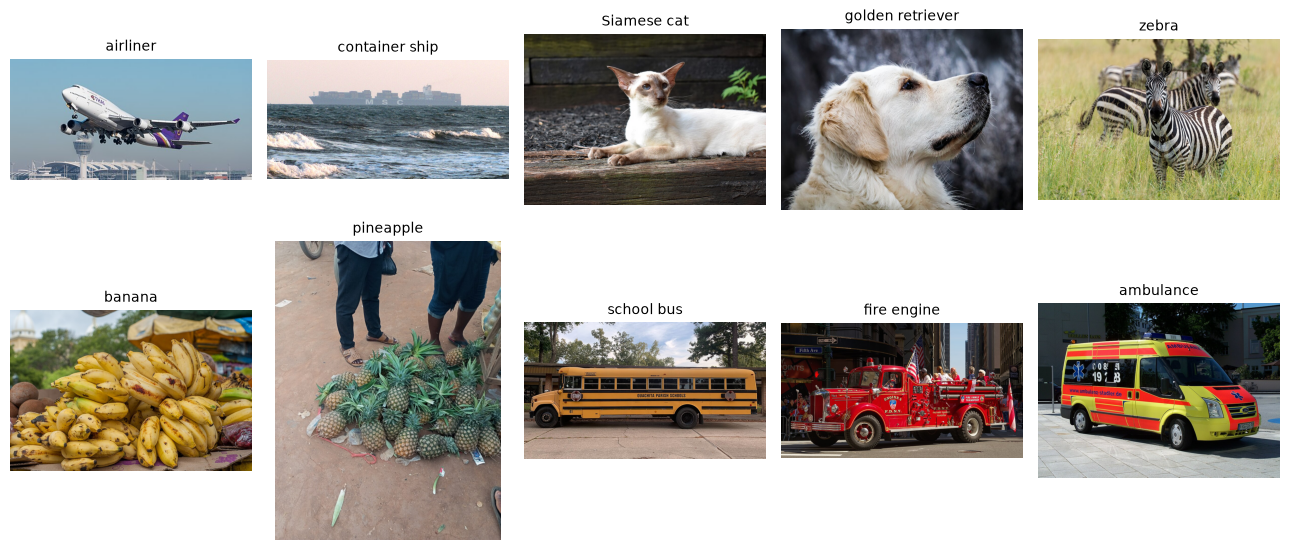

In [5]:
fig, axs = plt.subplots(2, 5, figsize=(13, 6))
for ax, img, label in zip(axs.flat, imgs, labels['class']):
    ax.imshow(img)
    ax.set_title(label.replace('_', ' '), fontsize=10)
    ax.axis('off')
plt.tight_layout()
plt.show()

# Model

In [6]:
model_name = 'vgg16'
image_size = (224, 224)
model = VGG16(weights='imagenet', include_top=True)
model.summary()

Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc1 (Dense)                     │ (None, 4096)           │   102,764,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc2 (Dense)                     │ (None, 4096)           │    16,781,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 1000)           │     4,097,000 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 138,357,544 (527.79 MB)

 Trainable params: 138,357,544 (527.79 MB)

 Non-trainable params: 0 (0.00 B)

# Preprocessing

In [1]:
# resize the image without cropping, convert RGB to BGR and subtracts channel means

In [7]:
resized_imgs = []
for img in imgs:
    img = img.resize(image_size, Image.Resampling.BILINEAR)
    resized_imgs.append(np.asarray(img, dtype='float32'))
resized_imgs = np.array(resized_imgs)

In [8]:
x = preprocess_input(resized_imgs.copy())
print('Input shape:', x.shape)
print('Pixel range:', x.min(), x.max())

Input shape: (10, 224, 224, 3)
Pixel range: -123.68 151.061


# Recognition

In [9]:
probabilities = model.predict(x, batch_size=2, verbose=0)
decoded = decode_predictions(probabilities, top=5)

In [10]:
rows = []
for record, predictions in zip(records, decoded):
    synset, label, confidence = predictions[0]
    top_synsets = [prediction[0] for prediction in predictions]
    top3 = [f'{label} ({score:.1%})' for _, label, score in predictions[:3]]
    rows.append({
        'image': record['file'],
        'class': record['class'],
        'expected_synset': record['synset'],
        'prediction': label,
        'predicted_synset': synset,
        'confidence': float(confidence),
        'top1_correct': synset == record['synset'],
        'top5_correct': record['synset'] in top_synsets,
        'top3': ', '.join(top3)
    })
results = pd.DataFrame(rows)
display(results[['image', 'class', 'prediction', 'confidence', 'top1_correct', 'top5_correct']])

,image,class,prediction,confidence,top1_correct,top5_correct
0,airliner.jpg,airliner,warplane,0.371039,False,True
1,container_ship.jpg,container_ship,promontory,0.345662,False,False
2,Siamese_cat.jpg,Siamese_cat,Siamese_cat,0.710488,True,True
3,golden_retriever.jpg,golden_retriever,golden_retriever,0.837348,True,True
4,zebra.jpg,zebra,zebra,0.999793,True,True
5,banana.jpg,banana,banana,0.920825,True,True
6,pineapple.jpg,pineapple,pineapple,0.933740,True,True
7,school_bus.jpg,school_bus,school_bus,0.999998,True,True
8,fire_engine.jpg,fire_engine,fire_engine,0.988671,True,True
9,ambulance.jpg,ambulance,ambulance,0.985904,True,True


In [11]:
top_rows = []
for record, predictions in zip(records, decoded):
    for rank, (synset, label, confidence) in enumerate(predictions, start=1):
        top_rows.append({
            'image': record['file'],
            'rank': rank,
            'synset': synset,
            'prediction': label,
            'confidence': float(confidence),
            'correct': synset == record['synset']
        })
top_results = pd.DataFrame(top_rows)
display(top_results)

,image,rank,synset,prediction,confidence,correct
0,airliner.jpg,1,n04552348,warplane,3.710391e-01,False
1,airliner.jpg,2,n02690373,airliner,3.097145e-01,True
2,airliner.jpg,3,n04592741,wing,1.329163e-01,False
3,airliner.jpg,4,n02687172,aircraft_carrier,7.008027e-02,False
4,airliner.jpg,5,n04266014,space_shuttle,4.310867e-02,False
5,container_ship.jpg,1,n09399592,promontory,3.456620e-01,False
6,container_ship.jpg,2,n02894605,breakwater,2.624894e-01,False
7,container_ship.jpg,3,n09428293,seashore,1.554484e-01,False
8,container_ship.jpg,4,n09246464,cliff,5.705270e-02,False
9,container_ship.jpg,5,n02814860,beacon,3.172258e-02,False


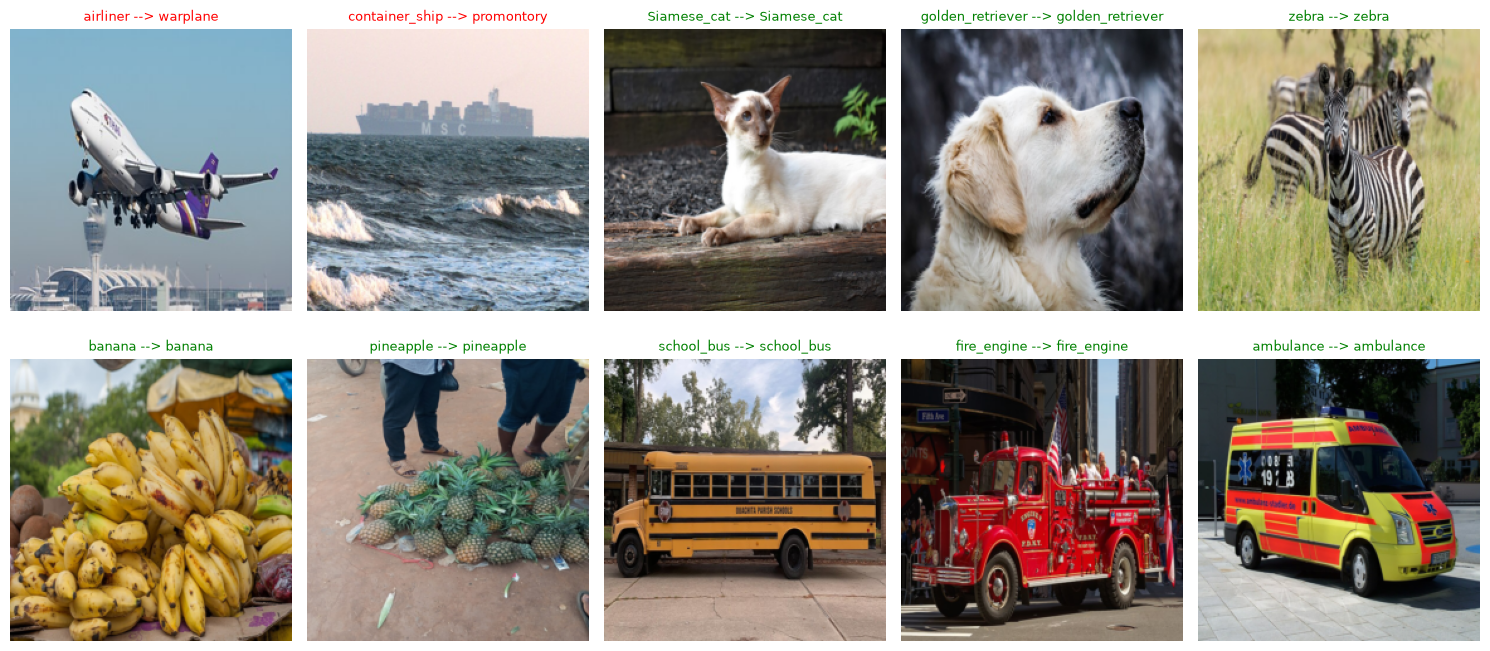

In [12]:
fig, axs = plt.subplots(2, 5, figsize=(15, 7))
for i, ax in enumerate(axs.flat):
    row = results.iloc[i]
    ax.imshow(resized_imgs[i].astype('uint8'))
    ax.set_title(
        f"{row['class']} --> {row['prediction']}",
        fontsize=9,
        color='green' if row['top1_correct'] else 'red'
    )
    ax.axis('off')
plt.tight_layout()
fig.savefig(f'results/{model_name}_predictions.png', dpi=150)
plt.show()

# Results

In [13]:
top1_accuracy = results['top1_correct'].mean()
top5_accuracy = results['top5_correct'].mean()
print(f'Top-1 accuracy: {top1_accuracy:.0%}')
print(f'Top-5 accuracy: {top5_accuracy:.0%}')

Top-1 accuracy: 80%
Top-5 accuracy: 90%


In [14]:
parameters = model.count_params()
weight_bytes = 0
for weight in model.weights:
    weight_bytes += int(np.prod(weight.shape)) * np.dtype(weight.dtype).itemsize
weights_mib = weight_bytes / 1024 ** 2
print(f'Parameters: {parameters:,}')
print(f'Weight memory: {weights_mib:.2f} MiB')

Parameters: 138,357,544
Weight memory: 527.79 MiB


In [15]:
timings = []
for _ in range(5):
    start = perf_counter()
    model.predict(x, batch_size=2, verbose=0)
    elapsed = perf_counter() - start
    timings.append(elapsed * 1000 / len(x))
inference_ms = float(np.median(timings))
print(f'Inference: {inference_ms:.2f} ms/image')

Inference: 17.66 ms/image


In [16]:
manifest_bytes = Path('images/manifest.json').read_bytes()
manifest_sha256 = hashlib.sha256(manifest_bytes).hexdigest()
metrics = {
    'model': model_name,
    'images': len(results),
    'top1_accuracy': float(top1_accuracy),
    'top5_accuracy': float(top5_accuracy),
    'parameters': parameters,
    'weights_mib': weights_mib,
    'input_size': list(image_size),
    'batch_size': 2,
    'inference_ms_per_image': inference_ms,
    'timings_ms_per_image': timings,
    'manifest_sha256': manifest_sha256,
    'tensorflow': tf.__version__,
    'keras': keras.__version__,
    'device': 'GPU' if tf.config.list_physical_devices('GPU') else 'CPU'
}

# Saving

In [17]:
results.to_csv(f'results/{model_name}_predictions.csv', index=False)
top_results.to_csv(f'results/{model_name}_top5.csv', index=False)
np.savez_compressed(
    f'results/{model_name}_probabilities.npz',
    probabilities=probabilities,
    images=np.array([fname.name for fname in img_files]),
    expected_indices=labels['index'].to_numpy()
)
Path(f'results/{model_name}_metrics.json').write_text(json.dumps(metrics, indent=4));

# Summary

**VGG16** використано з вагами ImageNet, без додаткового навчання. Зображення зменшено до 224x224, підготовка даних - перетворення RGB у BGR та віднімання середніх каналів. Точність top-1 - **80%**, top-5 - **90%**. Помилки top-1: `airliner.jpg` --> `warplane`; `container_ship.jpg` --> `promontory`.

Модель має **138,357,544 параметрів**. Медіанний час після прогріву - 17.66 мс на зображення при пакеті 2 на GPU.